### Hot tail generation Implementation

In [1]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [2]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

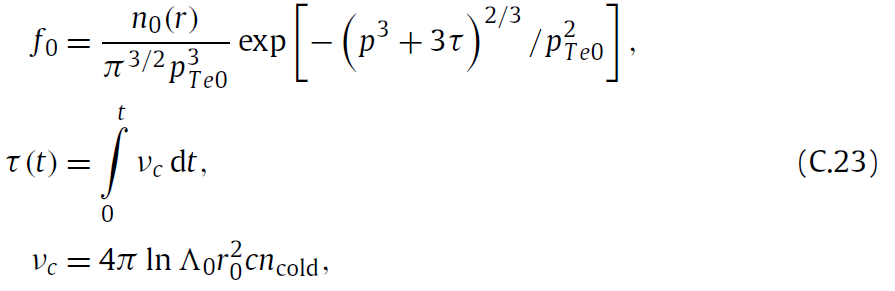

In [ ]:
# n_0 is density
# p_Te0 is normalized momentum
# tau(t) is nu_c * t if we ignore nu_cold
# nu_c is function of columb log and radius
# let r = 1, use getColombLog(n_0, T)
# initialize p as a array for a distribution (p vs f_0)
# T0 is initial temperature (idk i need to convert i think)
m = const.m_e # kg
e = const.e # C 
c = const.c # m/s

def getf0(p, n_0, T0, t, n_cold):
    '''
    
    '''

    

    #T0 = T0 
    p_Te0 = np.sqrt(2*T0*e/(m*c**2)) 
    r0 = const.physical_constants["classical electron radius"][0]
    nu_c = 4*np.pi * getCoulombLog(n_0, T0) * r0**2*c*n_cold
    tau = nu_c * t

    expo = -((p**3 + 3*tau)**(2/3)) / (p_Te0**2)

    return n_0/(np.pi**1.5 * p_Te0**3) * np.exp(expo) 



0.01851549622873723
54.00881443555028
18.05387763949107


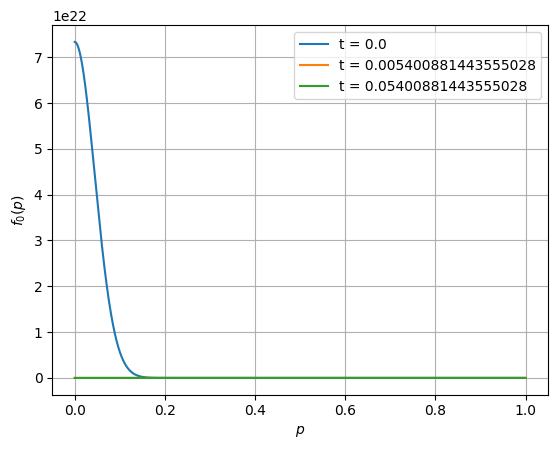

In [60]:
p  = np.linspace(0,1,10000)

n_0 = 1e20        # m^-3
n_cold = 1e20    # m^-3
T0 = 1e3           
r0 = const.physical_constants["classical electron radius"][0]
nu_c = 4*np.pi * getCoulombLog(n_0, T0) * r0**2*c*n_cold

print(1/nu_c)
print(nu_c)
print(getCoulombLog(n_0, T0))

t_list = [0, 10/nu_c, 20/nu_c, 40/nu_c, 80/nu_c]
t_list = np.array([0, 1e-4, 1e-3])

plt.figure()

for t in t_list:
    f0 = getf0(p, n_0, T0, t, n_cold)
    plt.plot(p, f0, label=rf"t = {t * nu_c}")

#plt.yscale("log")
plt.xlabel(r"$p$")
plt.ylabel(r"$f_0(p)$")
#plt.title("Eq. (C.23) distribution at $t=0$")
#plt.xlim()
plt.legend()
plt.grid(True)
plt.show()


0.021222163346995993
47.12054957118924
15.751292546497023


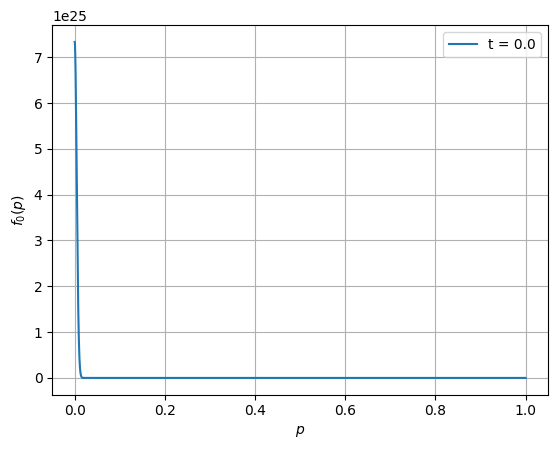

In [61]:
p  = np.linspace(0,1,10000)

n_0 = 1e20        # m^-3
n_cold = 1e20    # m^-3
T0 = 10           
r0 = const.physical_constants["classical electron radius"][0]
nu_c = 4*np.pi * getCoulombLog(n_0, T0) * r0**2*c*n_cold

print(1/nu_c)
print(nu_c)
print(getCoulombLog(n_0, T0))

t_list = [0]
#t_list = np.array([0, 1e-4, 1e-3])

plt.figure()

for t in t_list:
    f0 = getf0(p, n_0, T0, t, n_cold)
    plt.plot(p, f0, label=rf"t = {t * nu_c}")

#plt.yscale("log")
plt.xlabel(r"$p$")
plt.ylabel(r"$f_0(p)$")
#plt.title("Eq. (C.23) distribution at $t=0$")
#plt.xlim()
plt.legend()
plt.grid(True)
plt.show()
